In [1]:
# IMPORTS
import os
import sys
import ast
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

sys.path.append('../')
from utils.Evaluation.calculate_metrics import calculate_scores_benchmark_without_original_validation

# METRICS

In [ ]:
workflow_files = {
    '8B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/100_test_llama_3_1_8b_baseline.xlsx',
    '8B_Gen_Helper_History': 'Outputs_Evaluation/Movies_Experiment/GEN_HELPER_HISTORY/100_test_llama_3_1_8b_gen_helper_history.xlsx',
    '8B_Gen_Helper_Trajectory': 'Outputs_Evaluation/Movies_Experiment/GEN_HELPER_TRAJ/100_test_llama_3_1_8b_gen_helper_traj.xlsx',
    '8B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/100_test_llama_3_1_8b_history_only.xlsx',
    '8B_Trajectory_History': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_HISTORY/100_test_llama_3_1_8b_traj_history.xlsx',
    '8B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/100_test_llama_3_1_8b_traj_only.xlsx',
    '8B_Memory_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/100_test_llama_3_1_8b_mem_all_in.xlsx',

    '7B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/100_test_qwen_2_5_7b_baseline.xlsx',
    '7B_Gen_Helper_History': 'Outputs_Evaluation/Movies_Experiment/GEN_HELPER_HISTORY/100_test_qwen_2_5_7b_gen_helper_history.xlsx',
    '7B_Gen_Helper_Trajectory': 'Outputs_Evaluation/Movies_Experiment/GEN_HELPER_TRAJ/100_test_qwen_2_5_7b_gen_helper_traj.xlsx',
    '7B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/100_test_qwen_2_5_7b_history_only.xlsx',
    '7B_Trajectory_History': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_HISTORY/100_test_qwen_2_5_7b_traj_history.xlsx',
    '7B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/100_test_qwen_2_5_7b_traj_only.xlsx',
    '7B_Memory_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/100_test_qwen_2_5_7b_mem_all_in.xlsx',

    '3B_Baseline': 'Outputs_Evaluation/Movies_Experiment/BASELINE/100_test_llama_3_2_3b_baseline.xlsx',
    '3B_Gen_Helper_History': 'Outputs_Evaluation/Movies_Experiment/GEN_HELPER_HISTORY/100_test_llama_3_2_3b_gen_helper_history.xlsx',
    '3B_Gen_Helper_Trajectory': 'Outputs_Evaluation/Movies_Experiment/GEN_HELPER_TRAJ/100_test_llama_3_2_3b_gen_helper_traj.xlsx',
    '3B_History_Only': 'Outputs_Evaluation/Movies_Experiment/HISTORY_ONLY/100_test_llama_3_2_3b_history_only.xlsx',
    '3B_Trajectory_History': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_HISTORY/100_test_llama_3_2_3b_traj_history.xlsx',
    '3B_Trajectory_Only': 'Outputs_Evaluation/Movies_Experiment/TRAJECTORY_ONLY/100_test_llama_3_2_3b_traj_only.xlsx',
    '3B_Memory_All_In': 'Outputs_Evaluation/Movies_Experiment/MEMORY_ALL_IN/100_test_llama_3_2_3b_mem_all_in.xlsx'
}

model_mapping = {
    '8B': 'llama_3_1_8b',
    '7B': 'qwen_2_5_7b',
    '3B': 'llama_3_2_3b'
}

summary_results = []

def count_corrector_iterations(path):
    if pd.isna(path):
        return 0
    try:
        parsed_path = ast.literal_eval(str(path))
        if isinstance(parsed_path, list):
            return parsed_path.count('cypher_corrector')
    except (ValueError, SyntaxError):
        pass
    return str(path).count('cypher_corrector')

def is_evaluation_complete(df, expected_rows):
    if (
        len(df) != expected_rows
        or 'generated_cypher' not in df.columns
        or 'Syntax Valid' not in df.columns
    ):
        return False

    rows_to_evaluate = df['generated_cypher'].notna()

    return df.loc[
        rows_to_evaluate,
        'Syntax Valid'
    ].notna().all()

for config_name, file_path in workflow_files.items():
    print(f"\n--- Processing: {config_name} ---")

    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        continue

    model_key = config_name.split('_')[0]
    model_name = model_mapping[model_key]
    evaluated_path = f'Movies_Experiment_Metrics/{model_name}/{config_name}_evaluated.xlsx'

    workflow_df = pd.read_excel(file_path).astype(object)
    expected_rows = len(workflow_df)

    use_existing = False

    if os.path.exists(evaluated_path):
        existing_df = pd.read_excel(evaluated_path)

        if is_evaluation_complete(existing_df, expected_rows):
            print(f'Already evaluated: {evaluated_path}')
            evaluated_df = existing_df
            use_existing = True
        else:
            print(f'Incomplete evaluation found: {evaluated_path}')
            print('Resuming evaluation...')

    if not use_existing:
        evaluated_df = calculate_scores_benchmark_without_original_validation(
            model_name=model_name,
            model_name_pkl=f'{config_name}_evaluated',
            dataset='Movies_Experiment_Metrics',
            input_df=workflow_df
        )

    queries_count = len(evaluated_df)
    pass_score = pd.to_numeric(evaluated_df['Pass@1 Output'], errors='coerce').fillna(0).eq(1).sum()
    avg_loops = evaluated_df['path'].apply(count_corrector_iterations).mean()

    summary_results.append({
        'Configuration': config_name,
        'Queries': queries_count,
        'Pass@1 (%)': round((pass_score / queries_count) * 100, 2),
        'Mean Iterations': round(avg_loops, 2)
    })


--- Processing: 8B_Baseline ---
Already evaluated: Movies_Experiment_Metrics/llama3_1_8b/8B_Baseline_evaluated.xlsx

--- Processing: 8B_Gen_Helper_History ---
Already evaluated: Movies_Experiment_Metrics/llama3_1_8b/8B_Gen_Helper_History_evaluated.xlsx

--- Processing: 8B_Gen_Helper_Trajectory ---
Already evaluated: Movies_Experiment_Metrics/llama3_1_8b/8B_Gen_Helper_Trajectory_evaluated.xlsx

--- Processing: 8B_History_Only ---
Already evaluated: Movies_Experiment_Metrics/llama3_1_8b/8B_History_Only_evaluated.xlsx

--- Processing: 8B_Trajectory_History ---
Already evaluated: Movies_Experiment_Metrics/llama3_1_8b/8B_Trajectory_History_evaluated.xlsx

--- Processing: 8B_Trajectory_Only ---
Already evaluated: Movies_Experiment_Metrics/llama3_1_8b/8B_Trajectory_Only_evaluated.xlsx

--- Processing: 8B_Memory_All_In ---
Already evaluated: Movies_Experiment_Metrics/llama3_1_8b/8B_Memory_All_In_evaluated.xlsx

--- Processing: 7B_Baseline ---
Already evaluated: Movies_Experiment_Metrics/qwen_

# START OF DIAGRAMS 

In [ ]:
# ============================================================
# FILES
# ============================================================

metric_files = {
    '8B': {
        'Baseline': 'Movies_Experiment_Metrics/llama_3_1_8b/8B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'Movies_Experiment_Metrics/llama_3_1_8b/8B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'Movies_Experiment_Metrics/llama_3_1_8b/8B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'Movies_Experiment_Metrics/llama_3_1_8b/8B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'Movies_Experiment_Metrics/llama_3_1_8b/8B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'Movies_Experiment_Metrics/llama_3_1_8b/8B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'Movies_Experiment_Metrics/llama_3_1_8b/8B_Memory_All_In_evaluated.xlsx'
    },
    '7B': {
        'Baseline': 'Movies_Experiment_Metrics/qwen_2_5_7b/7B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'Movies_Experiment_Metrics/qwen_2_5_7b/7B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'Movies_Experiment_Metrics/qwen_2_5_7b/7B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'Movies_Experiment_Metrics/qwen_2_5_7b/7B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'Movies_Experiment_Metrics/qwen_2_5_7b/7B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'Movies_Experiment_Metrics/qwen_2_5_7b/7B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'Movies_Experiment_Metrics/qwen_2_5_7b/7B_Memory_All_In_evaluated.xlsx'
    },
    '3B': {
        'Baseline': 'Movies_Experiment_Metrics/llama_3_2_3b/3B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'Movies_Experiment_Metrics/llama_3_2_3b/3B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'Movies_Experiment_Metrics/llama_3_2_3b/3B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'Movies_Experiment_Metrics/llama_3_2_3b/3B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'Movies_Experiment_Metrics/llama_3_2_3b/3B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'Movies_Experiment_Metrics/llama_3_2_3b/3B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'Movies_Experiment_Metrics/llama_3_2_3b/3B_Memory_All_In_evaluated.xlsx'
    }
}

model_names = {
    '8B': 'Llama-3.1-8B-Instruct',
    '7B': 'Qwen-2.5-7B-Instruct',
    '3B': 'Llama-3.2-3B-Instruct'
}

config_names = {
    'Baseline': 'Baseline',
    'Gen_Helper_History': 'Gen Helper\n+ History',
    'Gen_Helper_Trajectory': 'Gen Helper\n+ Trajectory',
    'History_Only': 'History\nOnly',
    'Trajectory_History': 'Trajectory\n+ History',
    'Trajectory_Only': 'Trajectory\nOnly',
    'All_In': 'CyVerACT\nAll-In'
}

model_order = ['8B', '7B', '3B']

config_order = [
    'Baseline',
    'Gen_Helper_History',
    'Gen_Helper_Trajectory',
    'History_Only',
    'Trajectory_History',
    'Trajectory_Only',
    'All_In'
]

# ============================================================
# COLORS
# ============================================================

COLOR_FILTERED = '#2A9D8F'
COLOR_FULL = '#4A90E2'
COLOR_UNAVAILABLE = '#E32322'
COLOR_FILTERED_FAIL = '#A9D8D2'
COLOR_FULL_FAIL = '#B8D2F0'

# Pass@1 / Jaccard
COLOR_OUTPUT_FILTERED = '#23877D'   
COLOR_OUTPUT_FULL = "#1A83FB"       

COLOR_FILTERED_FAIL = "#77F5E4"
COLOR_FULL_FAIL = "#80BAFC"

# ============================================================
# HELPERS
# ============================================================

def normalize_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    if pd.api.types.is_numeric_dtype(series):
        return series.fillna(0).ne(0)
    s = series.fillna('').astype(str).str.strip().str.lower()
    return s.isin({'true', '1', 'yes', 'y', 't'})

def path_to_string(path):
    if path is None:
        return ''
    if isinstance(path, (list, tuple)):
        return ' -> '.join(str(x) for x in path)
    if pd.isna(path):
        return ''
    return str(path)

def get_schema_phase(row):
    if not row['final_kg_valid']:
        return 'Unavailable'

    path = path_to_string(row['path'])

    if 'schema_retriever' in path:
        return 'Full'

    return 'Filtered'

def count_local_iteration(row):
    phase = row['SchemaPhase']
    path = path_to_string(row['path'])

    if phase == 'Unavailable':
        return np.nan

    if phase == 'Filtered':
        filtered_path = path.split('schema_retriever', 1)[0]
        return filtered_path.count('cypher_corrector')

    if phase == 'Full':
        if 'schema_retriever' in path:
            full_path = path.split('schema_retriever', 1)[1]
            return full_path.count('cypher_corrector')

        return max(0, path.count('cypher_corrector') - 5)

    return np.nan

def get_iteration_color(base_color, iteration, max_iteration=5):
    rgb = np.array(mcolors.to_rgb(base_color))
    lighten = (int(iteration) / max_iteration) * 0.55
    new_rgb = rgb * (1 - lighten) + np.ones(3) * lighten
    return mcolors.to_hex(new_rgb)

# Only show outer percentages when slice >= 2%
def outer_autopct(pct):
    return f'{pct:.0f}%' if pct >= 2 else ''

# ============================================================
# LOAD DATA
# ============================================================

dfs = {}

for model_key, configs in metric_files.items():
    dfs[model_key] = {}

    for config_name, path in configs.items():
        if not os.path.exists(path):
            print(f'File not found: {path}')
            continue

        df = pd.read_excel(path)

        df['final_kg_valid'] = normalize_bool(
            df['is_KG_Valid_correct']
        )

        df['SchemaPhase'] = df.apply(
            get_schema_phase,
            axis=1
        )

        df['Iteration'] = df.apply(
            count_local_iteration,
            axis=1
        )

        dfs[model_key][config_name] = df

os.makedirs('Figures', exist_ok=True)

metrics_order = [
    'KG Valid',
    'Pass@1',
    'Positive Jaccard',
    'BLEU',
    'Rouge-L F1',
    'Jaro Similarity',
    'Jaccard Similarity'
]

def numeric_column(df, column):
    return pd.to_numeric(df[column], errors='coerce').fillna(0)

def calculate_table_metrics(df):
    kg_valid = normalize_bool(df['is_KG_Valid_correct'])
    pass1 = numeric_column(df, 'Pass@1 Output')
    jaccard_output = numeric_column(df, 'Jaccard Output')
    bleu = numeric_column(df, 'BLEU')
    rouge = numeric_column(df, 'Rouge-L F1-score')
    jaro = numeric_column(df, 'Jaro Similarity')
    jaccard = numeric_column(df, 'Jaccard Similarity')

    return {
        'KG Valid': kg_valid.mean() * 100,
        'Pass@1': pass1.eq(1).mean() * 100,
        'Positive Jaccard': jaccard_output.gt(0).mean() * 100,
        'BLEU': bleu.mean() * 100,
        'Rouge-L F1': rouge.mean() * 100,
        'Jaro Similarity': jaro.mean() * 100,
        'Jaccard Similarity': jaccard.mean() * 100
    }

results = {}

for model_key in model_order:
    results[model_key] = {}
    for config_name in config_order:
        if config_name in dfs[model_key]:
            results[model_key][config_name] = calculate_table_metrics(dfs[model_key][config_name])

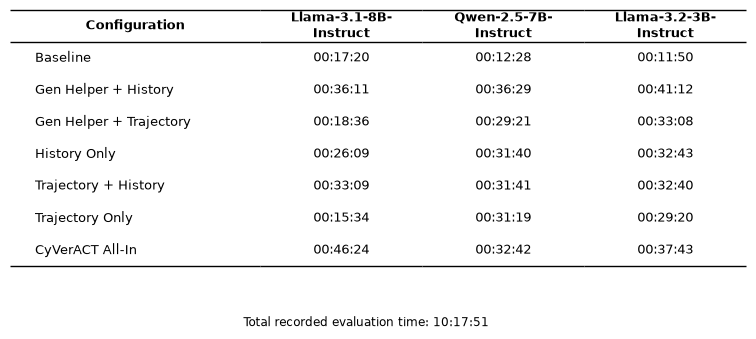

In [4]:
# ============================================================
# TOTAL EVALUATION TIME
# ============================================================

def fmt_time(s):
    h, r = divmod(int(s), 3600)
    m, s = divmod(r, 60)
    return f'{h:02d}:{m:02d}:{s:02d}'

data = []

for config in config_order:
    row = [config_names[config].replace('\n', ' ')]
    for model in model_order:
        t = pd.to_numeric(dfs[model][config]['eval_time_s'], errors='coerce')
        row.append(fmt_time(t.sum()))
    data.append(row)

total_time = sum(
    pd.to_numeric(dfs[m][c]['eval_time_s'], errors='coerce').sum()
    for m in model_order for c in config_order
)

columns = [
    'Configuration',
    'Llama-3.1-8B-\nInstruct',
    'Qwen-2.5-7B-\nInstruct',
    'Llama-3.2-3B-\nInstruct'
]

fig, ax = plt.subplots(figsize=(9.5, 3.7))
ax.axis('off')

table = ax.table(
    cellText=data, colLabels=columns,
    cellLoc='center', colLoc='center',
    bbox=[0, 0.10, 1, 0.90],
    colWidths=[0.34, 0.22, 0.22, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

for (r, c), cell in table.get_celld().items():
    cell.visible_edges = ''
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
    if c == 0 and r > 0:
        cell.get_text().set_ha('left')

for c in range(len(columns)):
    table[(len(data), c)].visible_edges = 'B'

fig.text(
    0.5, 0.025,
    f'Total recorded evaluation time: {fmt_time(total_time)}',
    ha='center', fontsize=8.5
)

os.makedirs('Figures/Movies_Dataset/Metric_Tables', exist_ok=True)

plt.savefig(
    'Figures/Movies_Dataset/Metric_Tables/total_evaluation_time.png',
    dpi=300, bbox_inches='tight', pad_inches=0.05
)

plt.show()

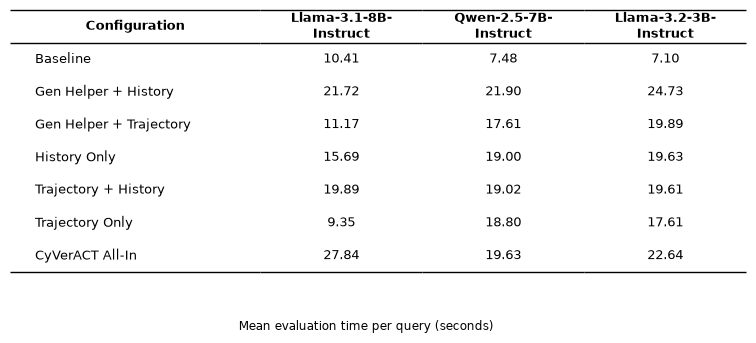

In [5]:
# ============================================================
# MEAN EVALUATION TIME PER QUERY
# ============================================================

data = []

for config in config_order:
    row = [config_names[config].replace('\n', ' ')]
    for model in model_order:
        t = pd.to_numeric(dfs[model][config]['eval_time_s'], errors='coerce')
        row.append(f'{t.mean():.2f}')
    data.append(row)

columns = [
    'Configuration',
    'Llama-3.1-8B-\nInstruct',
    'Qwen-2.5-7B-\nInstruct',
    'Llama-3.2-3B-\nInstruct'
]

fig, ax = plt.subplots(figsize=(9.5, 3.7))
ax.axis('off')

table = ax.table(
    cellText=data, colLabels=columns,
    cellLoc='center', colLoc='center',
    bbox=[0, 0.08, 1, 0.92],
    colWidths=[0.34, 0.22, 0.22, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

for (r, c), cell in table.get_celld().items():
    cell.visible_edges = ''
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
    if c == 0 and r > 0:
        cell.get_text().set_ha('left')

for c in range(len(columns)):
    table[(len(data), c)].visible_edges = 'B'

fig.text(
    0.5, 0.015,
    'Mean evaluation time per query (seconds)',
    ha='center', fontsize=8.5
)

plt.savefig(
    'Figures/Movies_Dataset/Metric_Tables/mean_eval_time_per_query.png',
    dpi=300, bbox_inches='tight', pad_inches=0.05
)

plt.show()

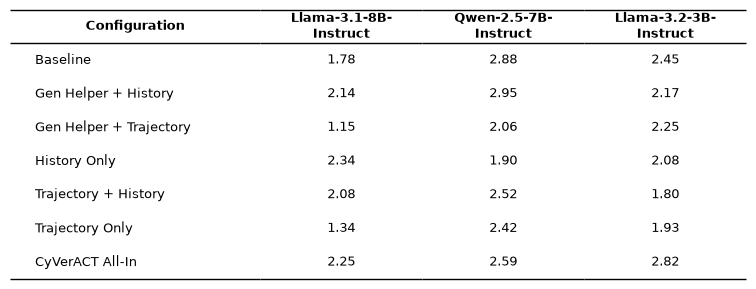

In [6]:
# ============================================================
# MEAN CORRECTOR ITERATIONS - KG VALID ONLY
# ============================================================

def count_corrector(path):
    return path_to_string(path).count('cypher_corrector')

data = []
for config in config_order:
    row = [config_names[config].replace('\n', ' ')]
    for model in model_order:
        df = dfs[model][config]
        valid = df[df['final_kg_valid']]
        row.append(f"{valid['path'].apply(count_corrector).mean():.2f}")
    data.append(row)

columns = [
    'Configuration',
    'Llama-3.1-8B-\nInstruct',
    'Qwen-2.5-7B-\nInstruct',
    'Llama-3.2-3B-\nInstruct'
]

fig, ax = plt.subplots(figsize=(9.5, 3.5))
ax.axis('off')

table = ax.table(
    cellText=data, colLabels=columns,
    cellLoc='center', colLoc='center',
    bbox=[0, 0, 1, 1],
    colWidths=[0.34, 0.22, 0.22, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

for (r, c), cell in table.get_celld().items():
    cell.visible_edges = ''
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
    if c == 0 and r > 0:
        cell.get_text().set_ha('left')

for c in range(len(columns)):
    table[(len(data), c)].visible_edges = 'B'

plt.savefig('Figures/Movies_Dataset/Metric_Tables/mean_corrector_iterations.png', dpi=300, bbox_inches='tight', pad_inches=0.05)

# plt.savefig('Figures/Movies_Dataset/Metric_Tables/mean_corrector_iterations.pdf', bbox_inches='tight', pad_inches=0.05)

plt.show()

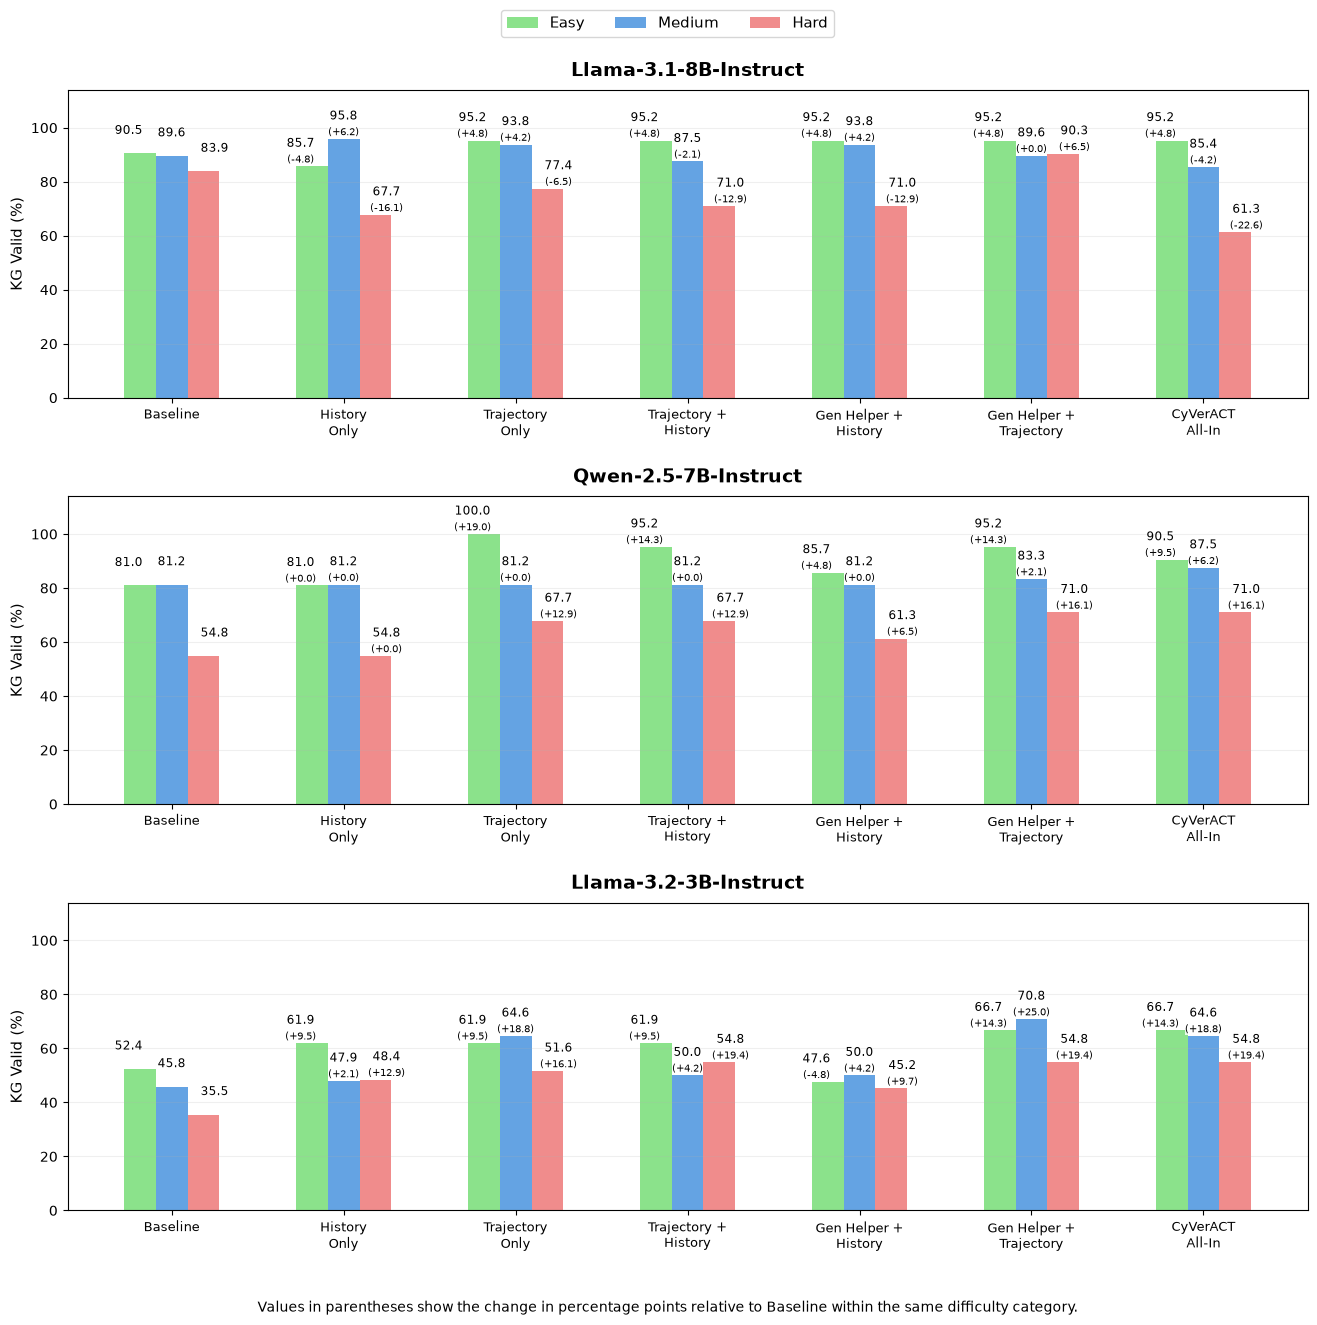

In [7]:
# ---------- KG VALID BY DIFFICULTY ----------

def categorize_complexity(query):
    q=str(query).upper()
    hard=r'\b(COLLECT|FILTER|UNWIND|WITH|FOREACH|REDUCE|CALL|YIELD|APOC)\b'
    medium=r'\b(ORDER BY|LIMIT|SKIP|COUNT|DISTINCT|EXISTS|IN|AND|OR|MIN|MAX|AVG|SUM)\b'
    if re.search(hard,q): return 'Hard'
    elif re.search(medium,q): return 'Medium'
    return 'Easy'

difficulty_order=['Easy','Medium','Hard']
difficulty_colors={'Easy':'#8BE28B','Medium':'#64A3E3','Hard':'#F08C8C'}

plot_config_order=['Baseline','History_Only','Trajectory_Only','Trajectory_History','Gen_Helper_History','Gen_Helper_Trajectory','All_In']
plot_config_labels={
    'Baseline':'Baseline','History_Only':'History\nOnly','Trajectory_Only':'Trajectory\nOnly',
    'Trajectory_History':'Trajectory +\nHistory','Gen_Helper_History':'Gen Helper +\nHistory',
    'Gen_Helper_Trajectory':'Gen Helper +\nTrajectory','All_In':'CyVerACT\nAll-In'
}

rows=[]
for model_key in model_order:
    for config_name in plot_config_order:
        df=pd.read_excel(metric_files[model_key][config_name])
        df['Difficulty']=df['cypher'].apply(categorize_complexity)
        df['final_kg_valid']=normalize_bool(df['is_KG_Valid_correct'])
        for difficulty in difficulty_order:
            subset=df[df['Difficulty']==difficulty]
            rows.append({'Model':model_key,'Configuration':config_name,'Difficulty':difficulty,'KG Valid (%)':subset['final_kg_valid'].mean()*100})

difficulty_results=pd.DataFrame(rows)

baseline_values={}
for model_key in model_order:
    baseline_values[model_key]={}
    for difficulty in difficulty_order:
        baseline_values[model_key][difficulty]=difficulty_results[
            (difficulty_results['Model']==model_key) &
            (difficulty_results['Configuration']=='Baseline') &
            (difficulty_results['Difficulty']==difficulty)
        ]['KG Valid (%)'].iloc[0]

difficulty_results['Delta']=difficulty_results.apply(lambda r:r['KG Valid (%)']-baseline_values[r['Model']][r['Difficulty']],axis=1)

fig,axes=plt.subplots(3,1,figsize=(16,13.5),sharey=True)

bar_width=0.20
x=np.arange(len(plot_config_order))*1.08
offsets={'Easy':-bar_width,'Medium':0,'Hard':bar_width}

value_offsets={'Easy':(-8,12),'Medium':(0,12),'Hard':(8,12)}
delta_offsets={'Easy':(-8,1),'Medium':(0,1),'Hard':(8,1)}

for ax,model_key in zip(axes,model_order):
    model_df=difficulty_results[difficulty_results['Model']==model_key]

    for difficulty in difficulty_order:
        values=[]; deltas=[]
        for config_name in plot_config_order:
            result=model_df[(model_df['Configuration']==config_name) & (model_df['Difficulty']==difficulty)]
            values.append(result['KG Valid (%)'].iloc[0])
            deltas.append(result['Delta'].iloc[0])

        bars=ax.bar(x+offsets[difficulty],values,width=bar_width,label=difficulty,color=difficulty_colors[difficulty])

        for i,(bar,value,delta) in enumerate(zip(bars,values,deltas)):
            xpos=bar.get_x()+bar.get_width()/2
            vx,vy=value_offsets[difficulty]

            ax.annotate(
                f'{value:.1f}',
                xy=(xpos,value),xytext=(vx,vy),textcoords='offset points',
                ha='center',va='bottom',fontsize=8.3,clip_on=False,zorder=6
            )

            if plot_config_order[i]!='Baseline':
                dx,dy=delta_offsets[difficulty]
                ax.annotate(
                    f'({delta:+.1f})',
                    xy=(xpos,value),xytext=(dx,dy),textcoords='offset points',
                    ha='center',va='bottom',fontsize=7.2,
                    bbox=dict(facecolor='white',edgecolor='none',alpha=0.80,pad=0.10),
                    clip_on=False,zorder=5
                )

    ax.set_title(model_names[model_key],fontsize=14,fontweight='bold',pad=10)
    ax.set_ylabel('KG Valid (%)',fontsize=11)
    ax.set_ylim(0,114)
    ax.set_xticks(x)
    ax.set_xticklabels([plot_config_labels[c] for c in plot_config_order],fontsize=9)
    ax.tick_params(axis='y',labelsize=10)
    ax.grid(axis='y',alpha=0.20)

handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=3,bbox_to_anchor=(0.5,0.985),fontsize=11,frameon=True)

fig.text(
    0.5,0.015,
    'Values in parentheses show the change in percentage points relative to Baseline within the same difficulty category.',
    ha='center',fontsize=10
)

plt.subplots_adjust(top=0.92,bottom=0.09,hspace=0.32)
plt.savefig('Figures/Movies_Dataset/Diagrams/kg_valid_by_difficulty.png',dpi=300,bbox_inches='tight')
plt.savefig('Figures/Movies_Dataset/Diagrams/kg_valid_by_difficulty.pdf',bbox_inches='tight')
plt.show()

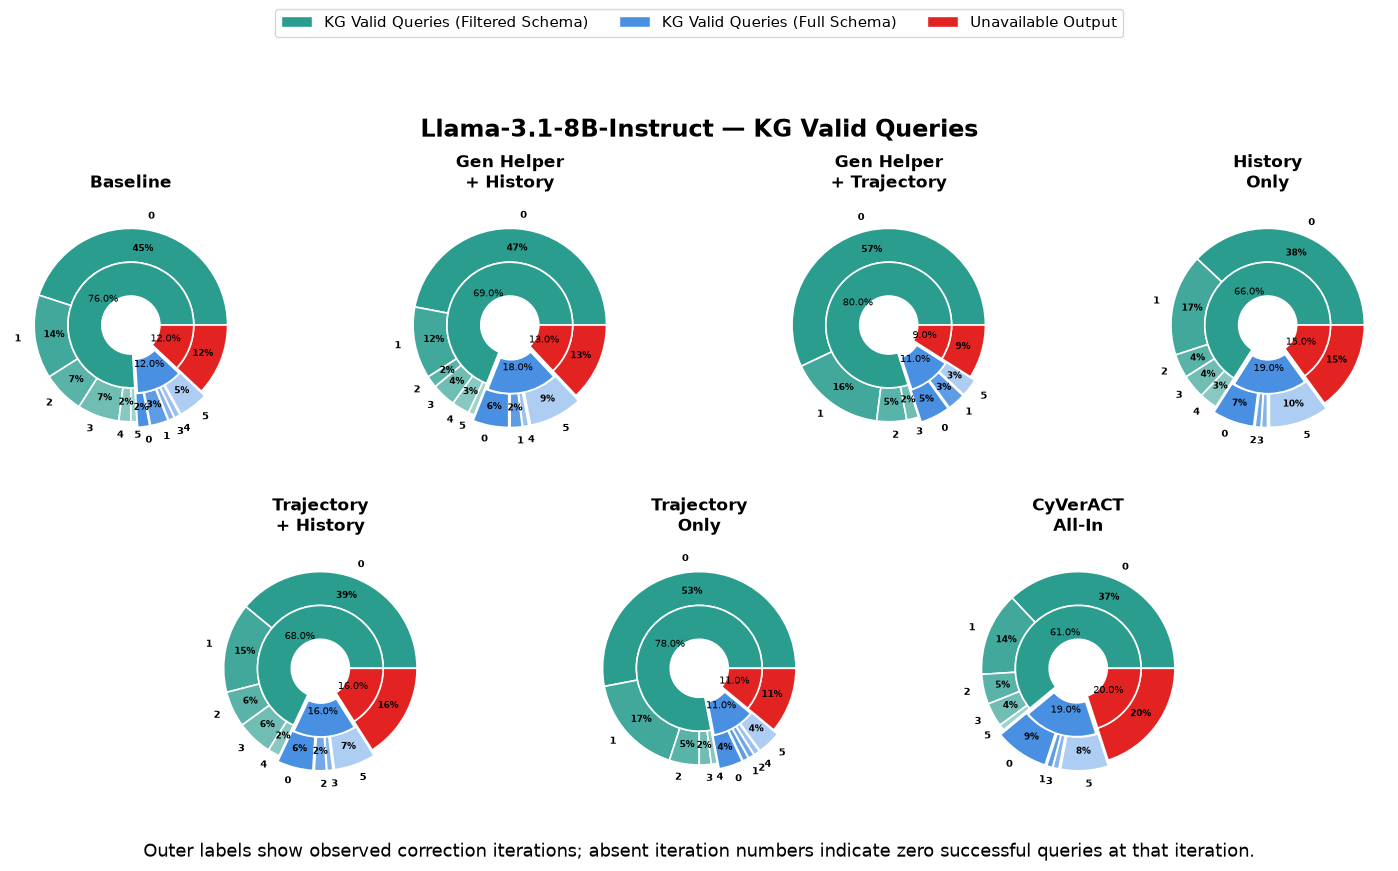

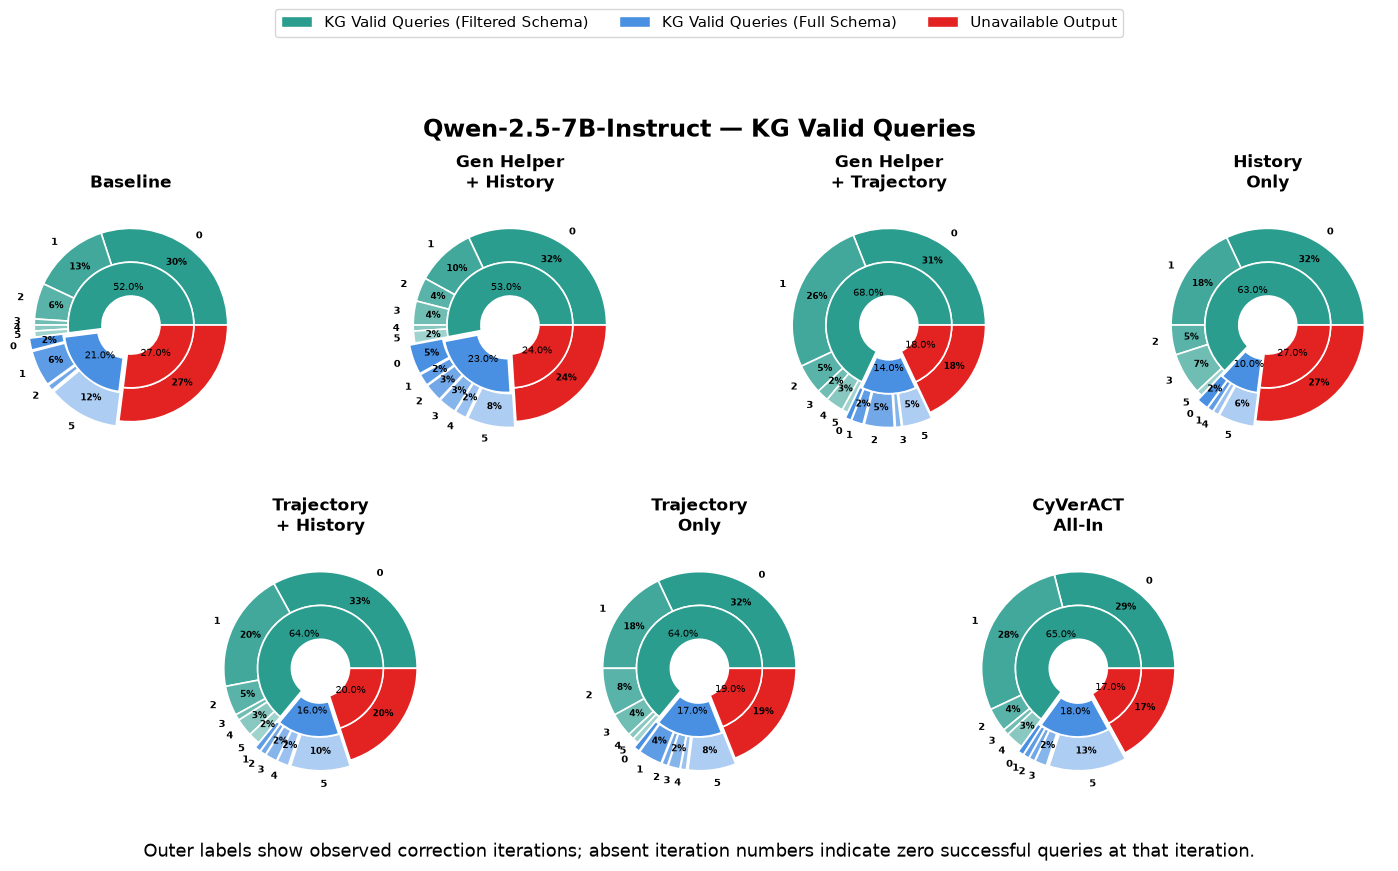

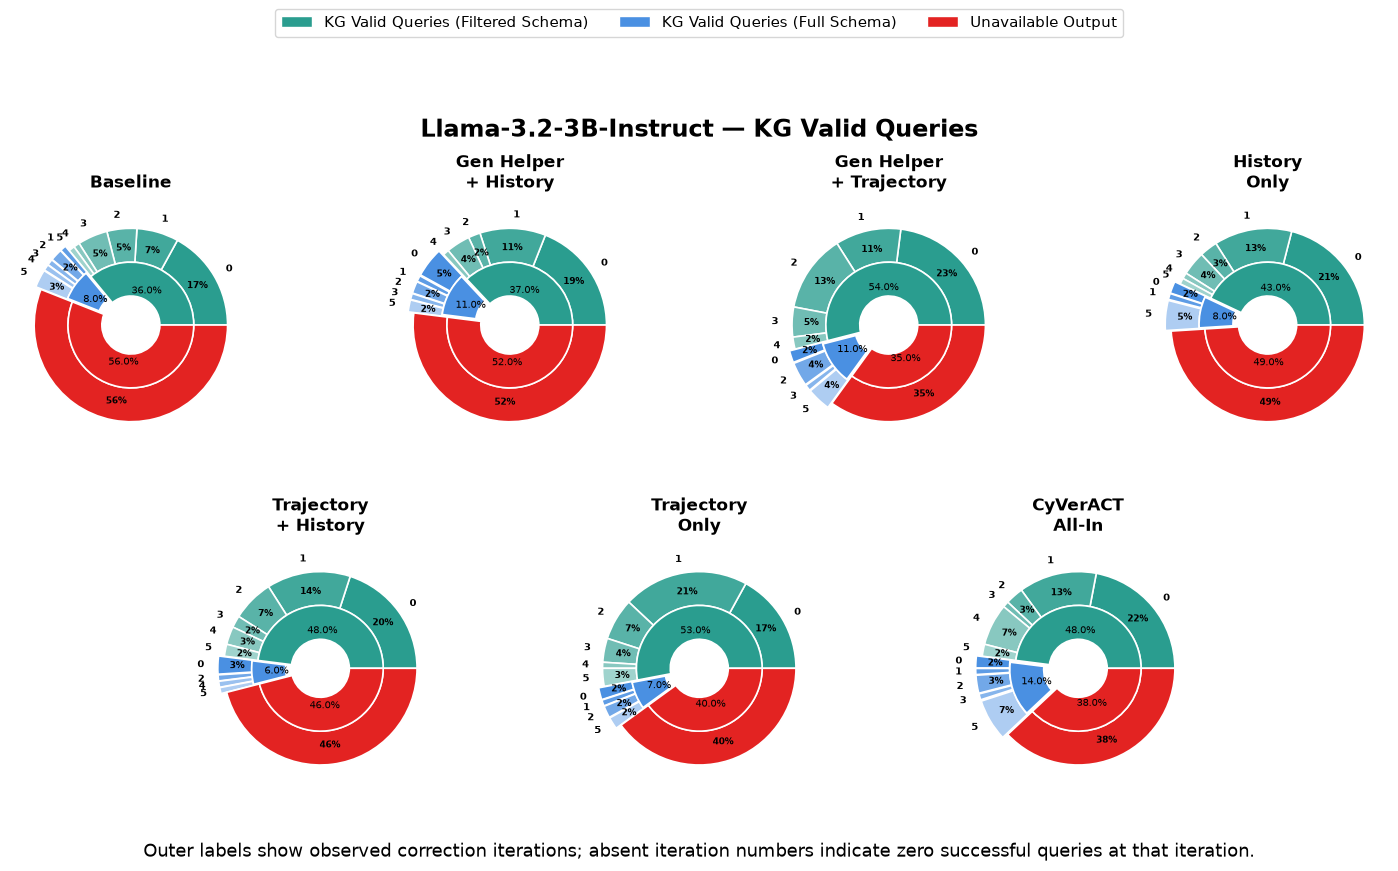

In [8]:
KG_FILTERED = 'KG Valid Queries (Filtered Schema)'
KG_FULL = 'KG Valid Queries (Full Schema)'
KG_UNAVAILABLE = 'Unavailable Output'

kg_categories = [KG_FILTERED, KG_FULL, KG_UNAVAILABLE]

kg_colors = {
    KG_FILTERED: COLOR_FILTERED,
    KG_FULL: COLOR_FULL,
    KG_UNAVAILABLE: COLOR_UNAVAILABLE
}

kg_legend = [
    Patch(facecolor=kg_colors[KG_FILTERED], edgecolor='white', label=KG_FILTERED),
    Patch(facecolor=kg_colors[KG_FULL], edgecolor='white', label=KG_FULL),
    Patch(facecolor=kg_colors[KG_UNAVAILABLE], edgecolor='white', label=KG_UNAVAILABLE)
]

for model_key in model_order:
    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(
        2, 8,
        left=0.04, right=0.96,
        bottom=0.11, top=0.76,
        wspace=0.30, hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=kg_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=3,
        fontsize=11,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — KG Valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.855
    )

    ring_width = 0.35

    # Small visual separation between Filtered and Full Schema
    KG_GROUP_GAP = 0.06
    kg_explode_map = {
        KG_FILTERED: 0.00,
        KG_FULL: KG_GROUP_GAP,
        KG_UNAVAILABLE: 0.00
    }

    for idx, config_name in enumerate(config_order):
        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()

        df['PlotCategory'] = KG_UNAVAILABLE
        df.loc[df['SchemaPhase'] == 'Filtered', 'PlotCategory'] = KG_FILTERED
        df.loc[df['SchemaPhase'] == 'Full', 'PlotCategory'] = KG_FULL

        inner_sizes = []
        inner_colors = []
        inner_explode = []

        for category in kg_categories:
            count = (df['PlotCategory'] == category).sum()

            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(kg_colors[category])
                inner_explode.append(kg_explode_map[category])

        outer_sizes = []
        outer_colors = []
        outer_labels = []
        outer_explode = []

        for category in kg_categories:
            sub_df = df[df['PlotCategory'] == category]

            if sub_df.empty:
                continue

            if category == KG_UNAVAILABLE:
                outer_sizes.append(len(sub_df))
                outer_colors.append(kg_colors[category])
                outer_labels.append('')
                outer_explode.append(kg_explode_map[category])
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .sort_index()
            )

            for iteration, count in iteration_counts.items():
                outer_sizes.append(count)
                outer_colors.append(
                    get_iteration_color(
                        kg_colors[category],
                        iteration
                    )
                )
                outer_labels.append(str(iteration))
                outer_explode.append(kg_explode_map[category])

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            explode=outer_explode,
            labeldistance=1.14,
            autopct=outer_autopct,
            pctdistance=0.80,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        _, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            explode=inner_explode,
            autopct='%1.1f%%',
            pctdistance=0.60,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in inner_autotexts:
            text.set_fontsize(7)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5, 0.035,
        'Outer labels show observed correction iterations; absent iteration numbers indicate zero successful queries at that iteration.',
        ha='center',
        fontsize=13
    )

    plt.savefig(
        f'Figures/Movies_Dataset/Diagrams/kg_valid_{model_key}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.savefig(f'Figures/Movies_Dataset/Diagrams/kg_valid_{model_key}.pdf', bbox_inches='tight')

    plt.show()

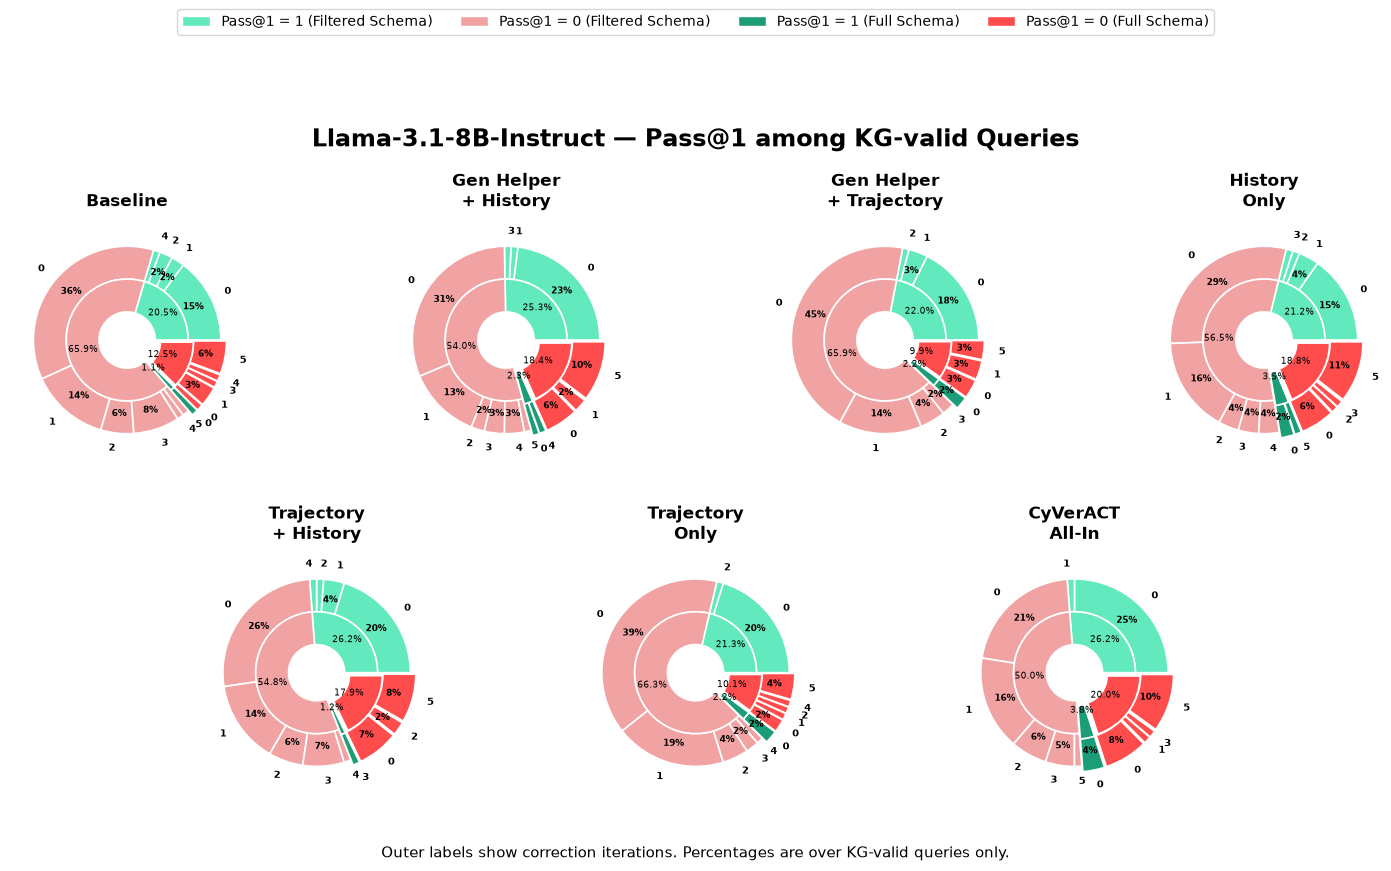

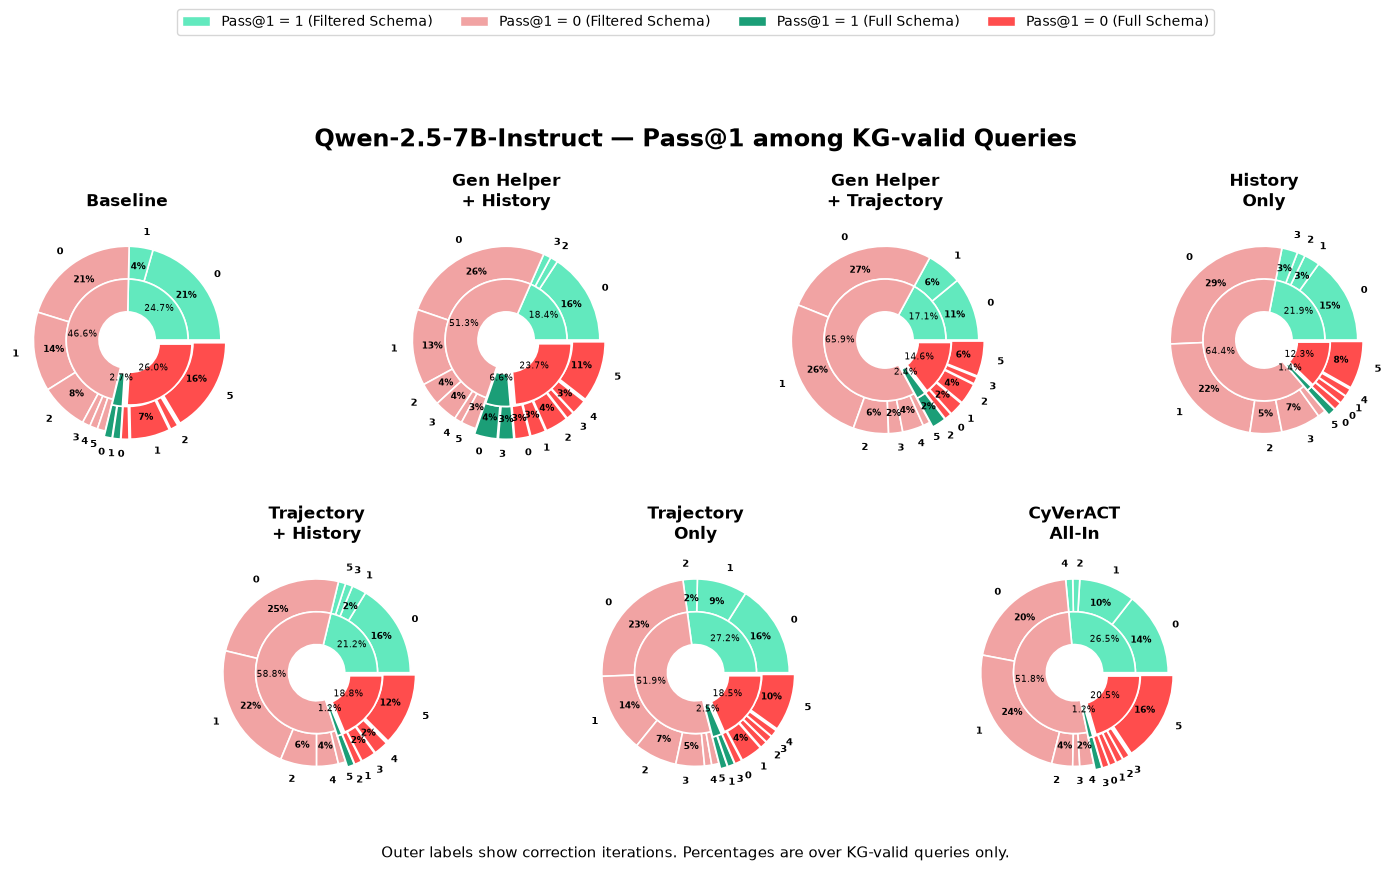

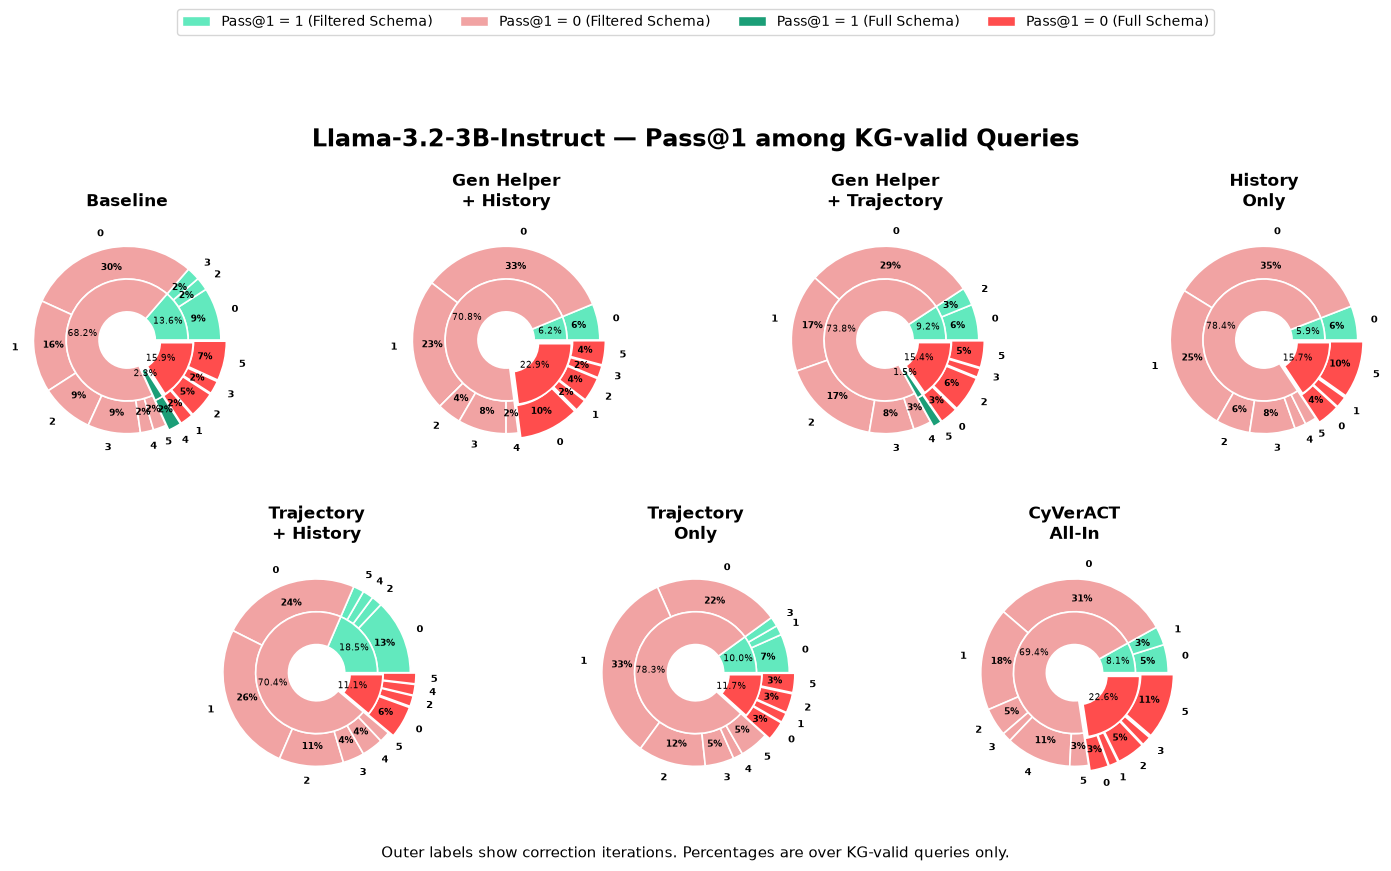

In [9]:
P1_FILTERED_SUCCESS = 'Pass@1 = 1 - Filtered'
P1_FILTERED_FAIL    = 'Pass@1 = 0 - Filtered'
P1_FULL_SUCCESS     = 'Pass@1 = 1 - Full'
P1_FULL_FAIL        = 'Pass@1 = 0 - Full'

PASS1_FILTERED_SUCCESS_COLOR = "#62e9be"
PASS1_FULL_SUCCESS_COLOR     = "#1b9e77"
PASS1_FILTERED_FAIL_COLOR    = "#f1a3a3"
PASS1_FULL_FAIL_COLOR        = "#ff4d4d"

# ------------------------------------------------------------
# ORDER: Filtered success -> Filtered fail -> Full success -> Full fail
# ------------------------------------------------------------
pass_categories = [
    P1_FILTERED_SUCCESS,
    P1_FILTERED_FAIL,
    P1_FULL_SUCCESS,
    P1_FULL_FAIL
]

pass_colors = {
    P1_FILTERED_SUCCESS: PASS1_FILTERED_SUCCESS_COLOR,
    P1_FILTERED_FAIL:    PASS1_FILTERED_FAIL_COLOR,
    P1_FULL_SUCCESS:     PASS1_FULL_SUCCESS_COLOR,
    P1_FULL_FAIL:        PASS1_FULL_FAIL_COLOR
}

pass_legend = [
    Patch(facecolor=PASS1_FILTERED_SUCCESS_COLOR, edgecolor='white',
          label='Pass@1 = 1 (Filtered Schema)'),
    Patch(facecolor=PASS1_FILTERED_FAIL_COLOR, edgecolor='white',
          label='Pass@1 = 0 (Filtered Schema)'),
    Patch(facecolor=PASS1_FULL_SUCCESS_COLOR, edgecolor='white',
          label='Pass@1 = 1 (Full Schema)'),
    Patch(facecolor=PASS1_FULL_FAIL_COLOR, edgecolor='white',
          label='Pass@1 = 0 (Full Schema)')
]

ITERATION_ORDER = [0, 1, 2, 3, 4, 5]

# same orientation as KG-valid
PIE_STARTANGLE = 0
PIE_COUNTERCLOCK = True

# small visual gap between filtered and full groups
GROUP_GAP = 0.06

pass_explode_map = {
    P1_FILTERED_SUCCESS: 0.00,
    P1_FILTERED_FAIL:    0.00,
    P1_FULL_SUCCESS:     GROUP_GAP,
    P1_FULL_FAIL:        GROUP_GAP
}

def pass1_outer_autopct(pct):
    return f'{pct:.0f}%' if pct >= 2 else ''

for model_key in model_order:
    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(
        2, 8,
        left=0.04,
        right=0.96,
        bottom=0.11,
        top=0.74,
        wspace=0.30,
        hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=pass_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=4,
        fontsize=10,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — Pass@1 among KG-valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.845
    )

    ring_width = 0.35

    for idx, config_name in enumerate(config_order):
        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()
        df = df[df['SchemaPhase'].isin(['Filtered', 'Full'])].copy()

        metric = pd.to_numeric(df['Pass@1 Output'], errors='coerce').fillna(0)

        df['PlotCategory'] = None
        df.loc[(df['SchemaPhase'] == 'Filtered') & metric.eq(1), 'PlotCategory'] = P1_FILTERED_SUCCESS
        df.loc[(df['SchemaPhase'] == 'Filtered') & metric.eq(0), 'PlotCategory'] = P1_FILTERED_FAIL
        df.loc[(df['SchemaPhase'] == 'Full')     & metric.eq(1), 'PlotCategory'] = P1_FULL_SUCCESS
        df.loc[(df['SchemaPhase'] == 'Full')     & metric.eq(0), 'PlotCategory'] = P1_FULL_FAIL

        inner_sizes = []
        inner_colors = []
        inner_categories = []
        inner_explode = []

        for category in pass_categories:
            count = (df['PlotCategory'] == category).sum()
            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(pass_colors[category])
                inner_categories.append(category)
                inner_explode.append(pass_explode_map[category])

        outer_sizes = []
        outer_colors = []
        outer_labels = []
        outer_explode = []

        for category in pass_categories:
            sub_df = df[df['PlotCategory'] == category]
            if sub_df.empty:
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .to_dict()
            )

            for iteration in ITERATION_ORDER:
                count = iteration_counts.get(iteration, 0)
                if count > 0:
                    outer_sizes.append(count)
                    outer_colors.append(pass_colors[category])
                    outer_labels.append(str(iteration))
                    outer_explode.append(pass_explode_map[category])

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            explode=outer_explode,
            labeldistance=1.16,
            autopct=pass1_outer_autopct,
            pctdistance=0.79,
            startangle=PIE_STARTANGLE,
            counterclock=PIE_COUNTERCLOCK,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        inner_wedges, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            explode=inner_explode,
            autopct='%1.1f%%',
            pctdistance=0.60,
            startangle=PIE_STARTANGLE,
            counterclock=PIE_COUNTERCLOCK,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        inner_radii = {
            P1_FILTERED_SUCCESS: 0.48,
            P1_FILTERED_FAIL:    0.48,
            P1_FULL_SUCCESS:     0.35,
            P1_FULL_FAIL:        0.35
        }

        for wedge, text, category in zip(inner_wedges, inner_autotexts, inner_categories):
            angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
            radius = inner_radii[category]
            cx, cy = wedge.center
            text.set_position((cx + radius * np.cos(angle), cy + radius * np.sin(angle)))
            text.set_fontsize(6.5)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5, 0.035,
        'Outer labels show correction iterations. Percentages are over KG-valid queries only.',
        ha='center',
        fontsize=11
    )

    plt.savefig(f'Figures/Movies_Dataset/Diagrams/pass1_kg_valid_{model_key}.png', dpi=300, bbox_inches='tight')
    plt.savefig(f'Figures/Movies_Dataset/Diagrams/pass1_kg_valid_{model_key}.pdf', bbox_inches='tight')
    plt.show()

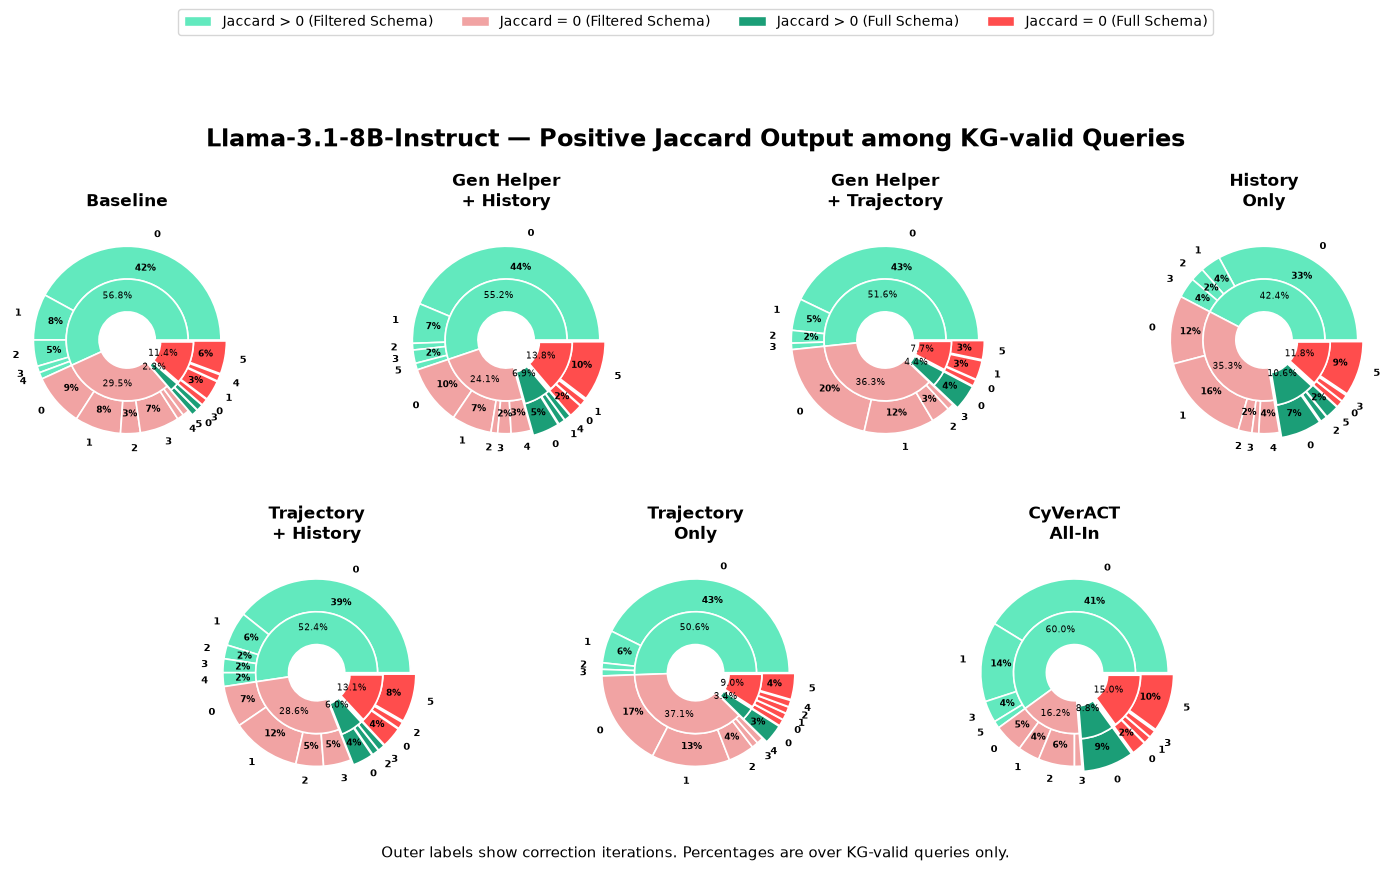

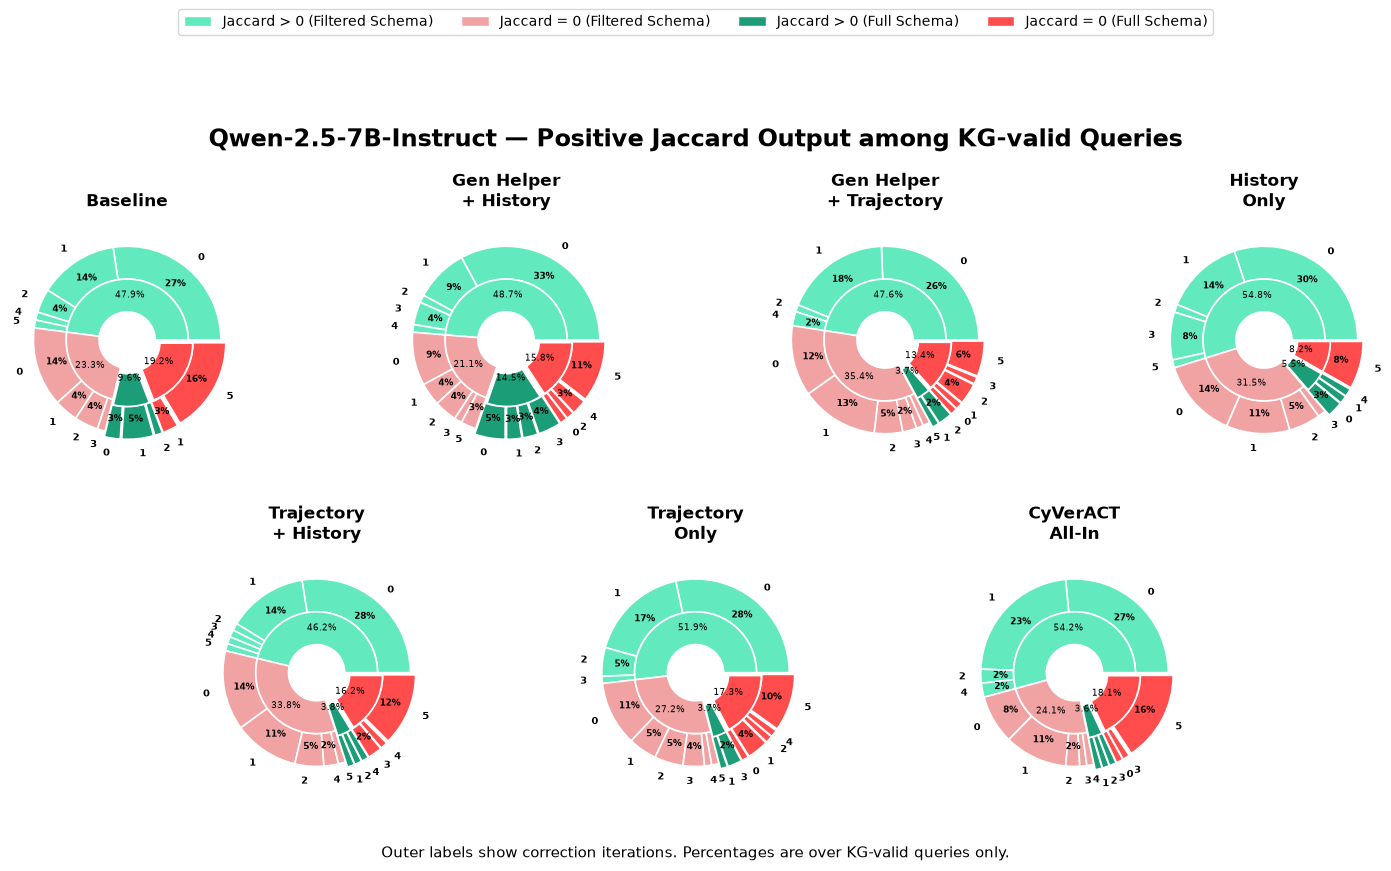

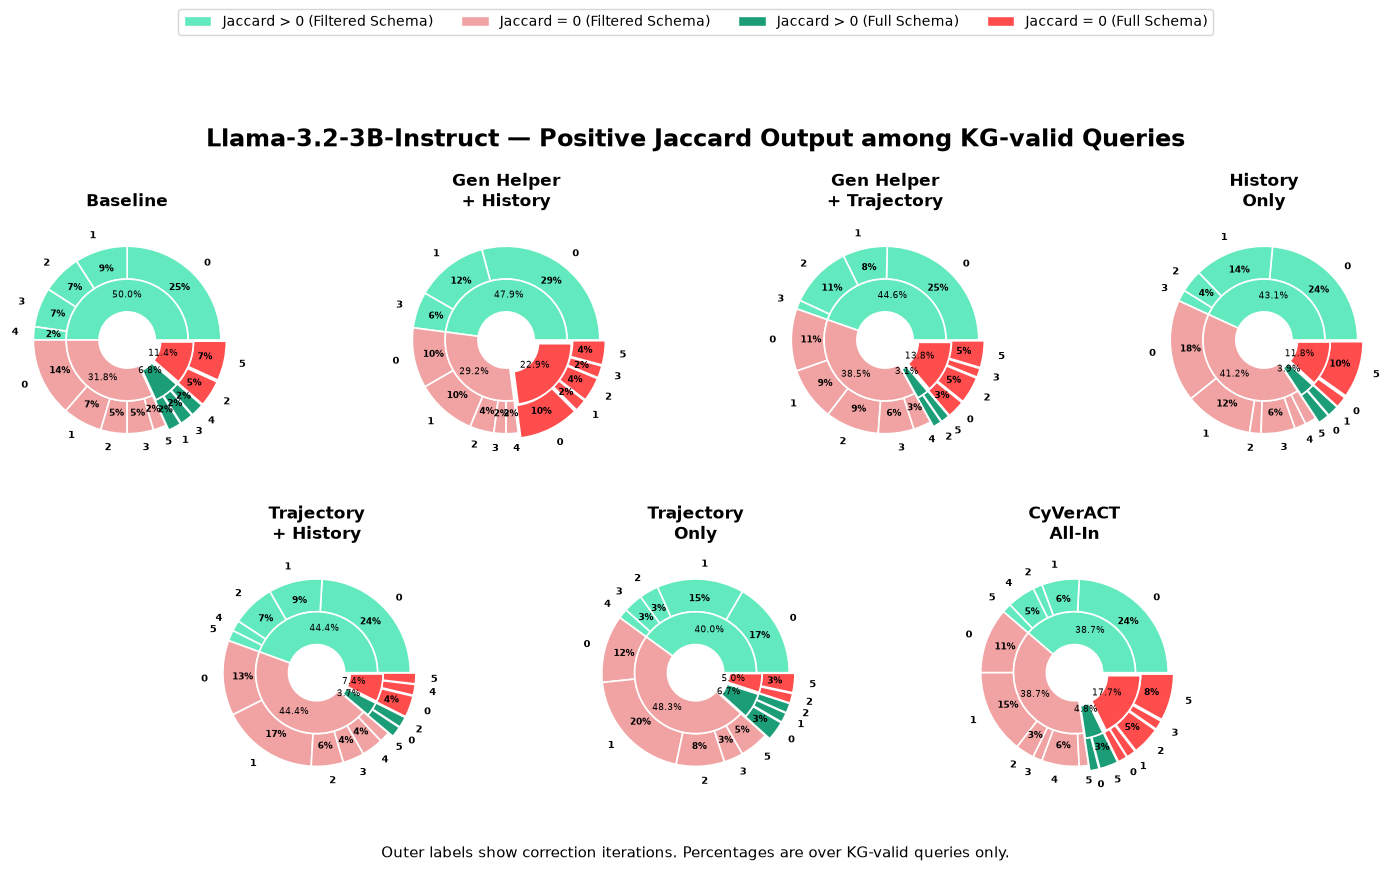

In [10]:
J_FILTERED_SUCCESS = 'Jaccard > 0 - Filtered'
J_FILTERED_FAIL    = 'Jaccard = 0 - Filtered'
J_FULL_SUCCESS     = 'Jaccard > 0 - Full'
J_FULL_FAIL        = 'Jaccard = 0 - Full'

JACCARD_FILTERED_SUCCESS_COLOR = "#62e9be"
JACCARD_FULL_SUCCESS_COLOR     = "#1b9e77"
JACCARD_FILTERED_FAIL_COLOR    = "#f1a3a3"
JACCARD_FULL_FAIL_COLOR        = "#ff4d4d"

# ------------------------------------------------------------
# ORDER: Filtered success -> Filtered fail -> Full success -> Full fail
# ------------------------------------------------------------
jaccard_categories = [
    J_FILTERED_SUCCESS,
    J_FILTERED_FAIL,
    J_FULL_SUCCESS,
    J_FULL_FAIL
]

jaccard_colors = {
    J_FILTERED_SUCCESS: JACCARD_FILTERED_SUCCESS_COLOR,
    J_FILTERED_FAIL:    JACCARD_FILTERED_FAIL_COLOR,
    J_FULL_SUCCESS:     JACCARD_FULL_SUCCESS_COLOR,
    J_FULL_FAIL:        JACCARD_FULL_FAIL_COLOR
}

jaccard_legend = [
    Patch(facecolor=JACCARD_FILTERED_SUCCESS_COLOR, edgecolor='white',
          label='Jaccard > 0 (Filtered Schema)'),
    Patch(facecolor=JACCARD_FILTERED_FAIL_COLOR, edgecolor='white',
          label='Jaccard = 0 (Filtered Schema)'),
    Patch(facecolor=JACCARD_FULL_SUCCESS_COLOR, edgecolor='white',
          label='Jaccard > 0 (Full Schema)'),
    Patch(facecolor=JACCARD_FULL_FAIL_COLOR, edgecolor='white',
          label='Jaccard = 0 (Full Schema)')
]

ITERATION_ORDER = [0, 1, 2, 3, 4, 5]

# same orientation as KG-valid
PIE_STARTANGLE = 0
PIE_COUNTERCLOCK = True

# small visual gap between filtered and full groups
GROUP_GAP = 0.06

jaccard_explode_map = {
    J_FILTERED_SUCCESS: 0.00,
    J_FILTERED_FAIL:    0.00,
    J_FULL_SUCCESS:     GROUP_GAP,
    J_FULL_FAIL:        GROUP_GAP
}

def jaccard_outer_autopct(pct):
    return f'{pct:.0f}%' if pct >= 2 else ''

for model_key in model_order:
    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(
        2, 8,
        left=0.04,
        right=0.96,
        bottom=0.11,
        top=0.74,
        wspace=0.30,
        hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=jaccard_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=4,
        fontsize=10,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — Positive Jaccard Output among KG-valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.845
    )

    ring_width = 0.35

    for idx, config_name in enumerate(config_order):
        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()
        df = df[df['SchemaPhase'].isin(['Filtered', 'Full'])].copy()

        metric = pd.to_numeric(df['Jaccard Output'], errors='coerce').fillna(0)

        df['PlotCategory'] = None
        df.loc[(df['SchemaPhase'] == 'Filtered') & metric.gt(0), 'PlotCategory'] = J_FILTERED_SUCCESS
        df.loc[(df['SchemaPhase'] == 'Filtered') & metric.eq(0), 'PlotCategory'] = J_FILTERED_FAIL
        df.loc[(df['SchemaPhase'] == 'Full')     & metric.gt(0), 'PlotCategory'] = J_FULL_SUCCESS
        df.loc[(df['SchemaPhase'] == 'Full')     & metric.eq(0), 'PlotCategory'] = J_FULL_FAIL

        inner_sizes = []
        inner_colors = []
        inner_categories = []
        inner_explode = []

        for category in jaccard_categories:
            count = (df['PlotCategory'] == category).sum()
            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(jaccard_colors[category])
                inner_categories.append(category)
                inner_explode.append(jaccard_explode_map[category])

        outer_sizes = []
        outer_colors = []
        outer_labels = []
        outer_explode = []

        for category in jaccard_categories:
            sub_df = df[df['PlotCategory'] == category]
            if sub_df.empty:
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .to_dict()
            )

            for iteration in ITERATION_ORDER:
                count = iteration_counts.get(iteration, 0)
                if count > 0:
                    outer_sizes.append(count)
                    outer_colors.append(jaccard_colors[category])
                    outer_labels.append(str(iteration))
                    outer_explode.append(jaccard_explode_map[category])

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            explode=outer_explode,
            labeldistance=1.16,
            autopct=jaccard_outer_autopct,
            pctdistance=0.79,
            startangle=PIE_STARTANGLE,
            counterclock=PIE_COUNTERCLOCK,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        inner_wedges, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            explode=inner_explode,
            autopct='%1.1f%%',
            pctdistance=0.60,
            startangle=PIE_STARTANGLE,
            counterclock=PIE_COUNTERCLOCK,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        inner_radii = {
            J_FILTERED_SUCCESS: 0.48,
            J_FILTERED_FAIL:    0.48,
            J_FULL_SUCCESS:     0.35,
            J_FULL_FAIL:        0.35
        }

        for wedge, text, category in zip(inner_wedges, inner_autotexts, inner_categories):
            angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
            radius = inner_radii[category]
            cx, cy = wedge.center
            text.set_position((cx + radius * np.cos(angle), cy + radius * np.sin(angle)))
            text.set_fontsize(6.5)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5, 0.035,
        'Outer labels show correction iterations. Percentages are over KG-valid queries only.',
        ha='center',
        fontsize=11
    )

    plt.savefig(f'Figures/Movies_Dataset/Diagrams/jaccard_kg_valid_{model_key}.png', dpi=300, bbox_inches='tight')
    plt.savefig(f'Figures/Movies_Dataset/Diagrams/jaccard_kg_valid_{model_key}.pdf', bbox_inches='tight')
    plt.show()

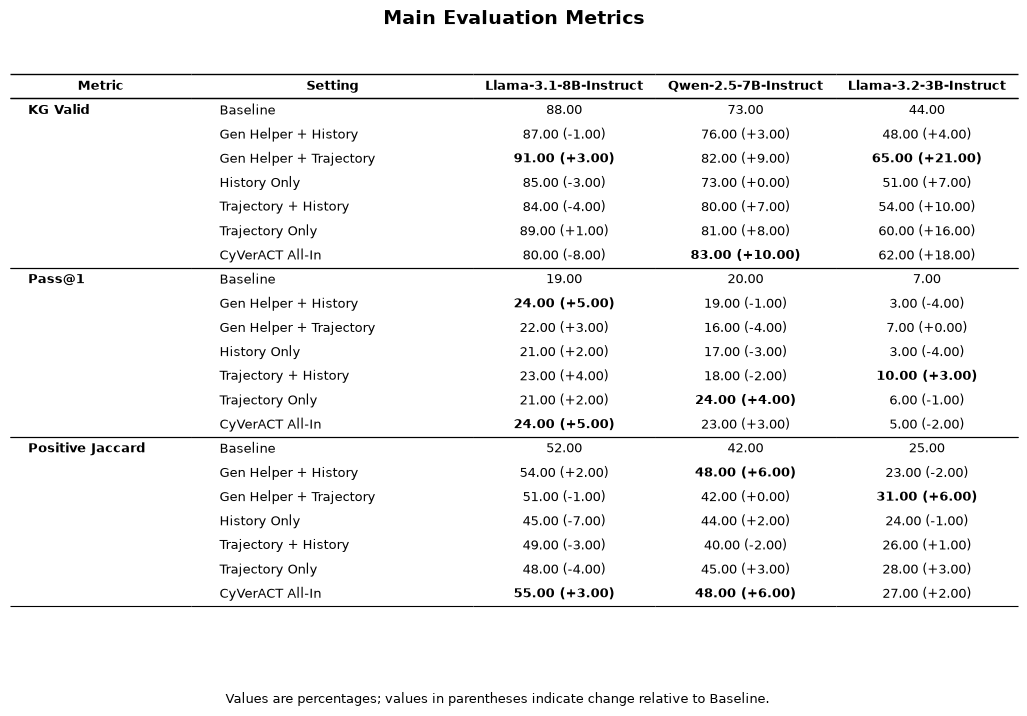

Saved: Figures/Movies_Dataset/Metric_Tables/main_metrics_table.png


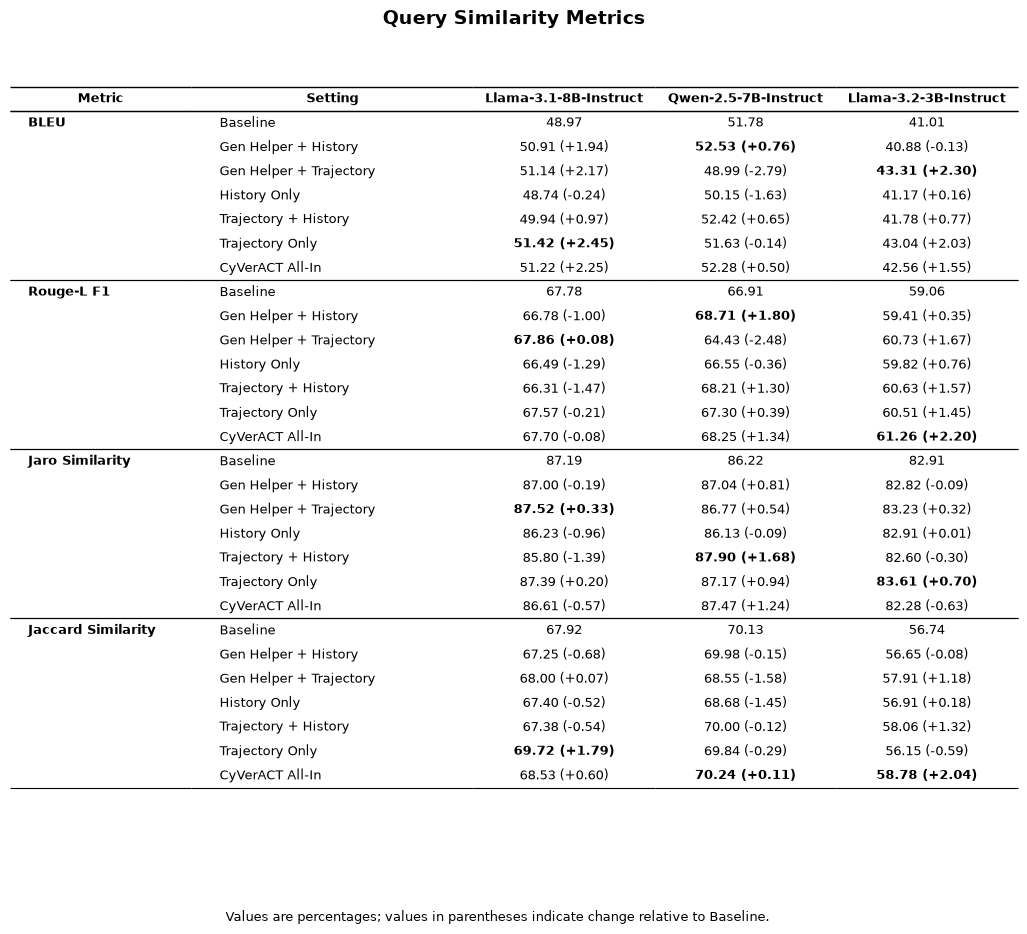

Saved: Figures/Movies_Dataset/Metric_Tables/similarity_metrics_table.png


In [11]:
os.makedirs('Figures/Movies_Dataset/Diagrams', exist_ok=True)
os.makedirs('Figures/Movies_Dataset/Metric_Tables', exist_ok=True)

table_config_names = {
    'Baseline': 'Baseline',
    'Gen_Helper_History': 'Gen Helper + History',
    'Gen_Helper_Trajectory': 'Gen Helper + Trajectory',
    'History_Only': 'History Only',
    'Trajectory_History': 'Trajectory + History',
    'Trajectory_Only': 'Trajectory Only',
    'All_In': 'CyVerACT All-In'
}

def create_metric_table(metrics, title, filename):
    rows = []
    numeric_rows = []

    for metric in metrics:
        for idx, config_name in enumerate(config_order):
            row = {
                'Metric': metric if idx == 0 else '',
                'Setting': table_config_names[config_name]
            }

            numeric_row = {
                'Metric': metric,
                'Setting': table_config_names[config_name]
            }

            for model_key in model_order:
                column = model_names[model_key]
                value = results[model_key][config_name][metric]
                numeric_row[column] = value

                if config_name == 'Baseline':
                    row[column] = f'{value:.2f}'
                else:
                    baseline = results[model_key]['Baseline'][metric]
                    row[column] = f'{value:.2f} ({value - baseline:+.2f})'

            rows.append(row)
            numeric_rows.append(numeric_row)

    display_df = pd.DataFrame(rows)
    numeric_df = pd.DataFrame(numeric_rows)

    fig_height = max(7, len(display_df) * 0.36)
    fig, ax = plt.subplots(figsize=(13, fig_height))
    ax.axis('off')

    table = ax.table(
        cellText=display_df.values,
        colLabels=display_df.columns,
        cellLoc='center',
        colLoc='center',
        loc='center',
        colWidths=[0.18, 0.28, 0.18, 0.18, 0.18]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1, 1.45)

    n_cols = len(display_df.columns)

    for col in range(n_cols):
        cell = table[(0, col)]
        cell.set_text_props(weight='bold')
        cell.visible_edges = 'TB'
        cell.set_linewidth(1.0)

    for row_idx in range(1, len(display_df) + 1):
        config_idx = (row_idx - 1) % len(config_order)

        for col in range(n_cols):
            cell = table[(row_idx, col)]
            cell.visible_edges = ''

            if config_idx == 0:
                cell.visible_edges = 'T'
                cell.set_linewidth(0.8)

            if config_idx == len(config_order) - 1:
                cell.visible_edges += 'B'
                cell.set_linewidth(0.8)

        table[(row_idx, 0)].get_text().set_ha('left')
        table[(row_idx, 1)].get_text().set_ha('left')

        if config_idx == 0:
            table[(row_idx, 0)].get_text().set_weight('bold')

    for metric_idx, metric in enumerate(metrics):
        metric_rows = numeric_df.index[numeric_df['Metric'] == metric]

        for model_idx, model_key in enumerate(model_order):
            column = model_names[model_key]
            values = numeric_df.loc[metric_rows, column]
            best = values.max()

            for dataframe_idx in values[np.isclose(values, best)].index:
                table[(dataframe_idx + 1, model_idx + 2)].get_text().set_weight('bold')

    ax.set_title(title, fontsize=14, fontweight='bold', pad=18)

    fig.text(
        0.5,
        0.015,
        'Values are percentages; values in parentheses indicate change relative to Baseline.',
        ha='center',
        fontsize=9
    )

    plt.savefig(f'Figures/Movies_Dataset/Metric_Tables/{filename}.png', dpi=300, bbox_inches='tight')
    #plt.savefig(f'Figures/Movies_Dataset/Metric_Tables/{filename}.pdf', bbox_inches='tight')
    plt.show()

    print(f'Saved: Figures/Movies_Dataset/Metric_Tables/{filename}.png')

main_metrics = [
'KG Valid',
'Pass@1',
'Positive Jaccard',
]

similarity_metrics = [
    'BLEU',
    'Rouge-L F1',
    'Jaro Similarity',
    'Jaccard Similarity'
]

create_metric_table(
    main_metrics,
    'Main Evaluation Metrics',
    'main_metrics_table'
)

create_metric_table(
    similarity_metrics,
    'Query Similarity Metrics',
    'similarity_metrics_table'
)

# END OF DIAGRAMS